# JS11 – Klasifikasi 2: Praktikum 4
## Klasifikasi Citra Wajah dengan PCA dan SVM

**Tujuan praktikum**

1. Mengunduh dan mengeksplorasi dataset wajah **Labeled Faces in the Wild (LFW)**.
2. Melakukan reduksi dimensi dengan **Principal Component Analysis (PCA)**.
3. Melatih SVM kernel RBF untuk mengenali identitas tokoh publik.
4. Melakukan **hyperparameter tuning** dengan `GridSearchCV`.
5. Mengevaluasi model dengan classification report dan confusion matrix.

**Tentang data:** `fetch_lfw_people(min_faces_per_person=60)` mengambil citra wajah dari 8 tokoh publik yang masing-masing memiliki minimal 60 foto. Setiap citra berukuran 62 × 47 piksel (hasil resize default 0,5) sehingga memiliki 2.914 fitur. Dataset ini tidak seimbang; George W. Bush memiliki jumlah foto terbanyak.

> PCA memproyeksikan 2.914 fitur piksel ke 150 komponen utama. SVM kemudian bekerja pada ruang fitur yang jauh lebih kecil. `class_weight='balanced'` membantu model tidak didominasi oleh kelas mayoritas.

### 0. Import library

In [1]:
import platform
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 6)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Mengunduh dataset

Dataset disimpan di folder `data/` agar notebook dapat dijalankan ulang tanpa mengunduh berkali-kali. Jika folder belum ada, scikit-learn akan mengunduh otomatis.

In [2]:
faces = fetch_lfw_people(
    data_home="data",
    min_faces_per_person=60,
    resize=0.5,
    color=False,
)

print("Nama tokoh:")
print(faces.target_names)
print("\nJumlah kelas:", len(faces.target_names))
print("Bentuk images:", faces.images.shape)
print("Bentuk data  :", faces.data.shape)
print("\nJumlah foto per tokoh:")
for name, count in zip(faces.target_names, np.bincount(faces.target)):
    print(f"- {name:20s}: {count}")

Nama tokoh:
['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']

Jumlah kelas: 8
Bentuk images: (1348, 62, 47)
Bentuk data  : (1348, 2914)

Jumlah foto per tokoh:
- Ariel Sharon        : 77
- Colin Powell        : 236
- Donald Rumsfeld     : 121
- George W Bush       : 530
- Gerhard Schroeder   : 109
- Hugo Chavez         : 71
- Junichiro Koizumi   : 60
- Tony Blair          : 144


### 2. Inspeksi citra wajah

Setiap gambar ditampilkan dalam grayscale. Label di bawah gambar adalah nama tokoh.

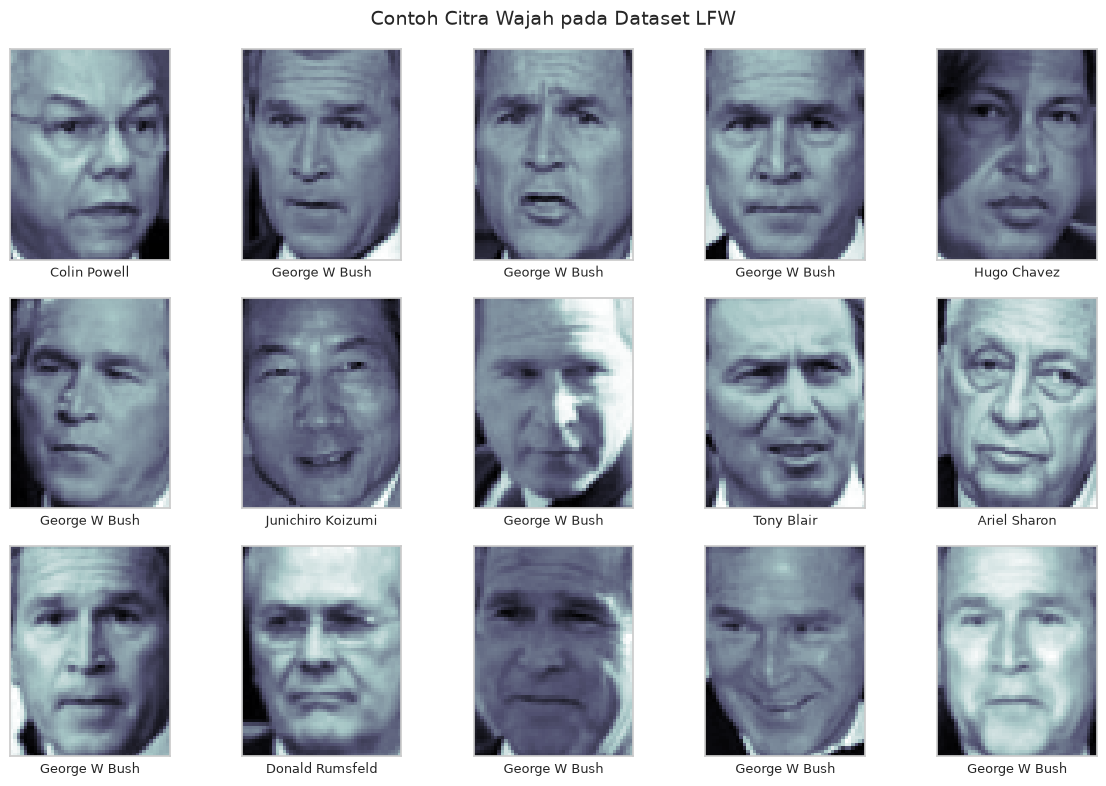

In [3]:
fig, ax = plt.subplots(3, 5, figsize=(12, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap="bone")
    axi.set(xticks=[], yticks=[])
    axi.set_xlabel(faces.target_names[faces.target[i]], fontsize=9)
plt.suptitle("Contoh Citra Wajah pada Dataset LFW", size=14)
plt.tight_layout()
plt.show()

### 3. Pipeline PCA + SVM dan pembagian data

Pipeline terdiri dari:

1. **PCA** dengan 150 komponen dan `whiten=True` untuk menormalkan variansi komponen.
2. **SVC** dengan kernel RBF dan `class_weight='balanced'`.

Data dibagi 75% latih dan 25% uji dengan stratifikasi kelas. Stratifikasi menjaga proporsi setiap tokoh pada data uji.

In [4]:
pca = PCA(
    n_components=150,
    whiten=True,
    random_state=42,
    svd_solver="randomized",
)
svc = SVC(kernel="rbf", class_weight="balanced")
model = make_pipeline(pca, svc)

X_train, X_test, y_train, y_test = train_test_split(
    faces.data,
    faces.target,
    test_size=0.25,
    random_state=42,
    stratify=faces.target,
)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)
print("Kelas latih:", np.bincount(y_train))
print("Kelas uji  :", np.bincount(y_test))

Data latih: (1011, 2914)
Data uji  : (337, 2914)
Kelas latih: [ 58 177  91 397  82  53  45 108]
Kelas uji  : [ 19  59  30 133  27  18  15  36]


### 4. Hyperparameter tuning dengan GridSearchCV

GridSearchCV mencoba kombinasi `C` dan `gamma` untuk kernel RBF. Setiap kombinasi dievaluasi dengan 5-fold cross-validation pada data latih.

- `C` mengontrol penalti kesalahan.
- `gamma` mengontrol luas pengaruh satu support vector.

Proses ini bisa memakan waktu karena setiap kombinasi melatih ulang PCA dan SVM.

In [5]:
param_grid = {
    "svc__C": [1, 5, 10, 50],
    "svc__gamma": [0.0001, 0.0005, 0.001, 0.005],
}

grid = GridSearchCV(
    model,
    param_grid,
    n_jobs=-1,
    verbose=0,
)

t0 = time.time()
grid.fit(X_train, y_train)
elapsed = time.time() - t0

print(f"Waktu pencarian: {elapsed:.2f} detik")
print("Parameter terbaik:", grid.best_params_)
print(f"Skor CV terbaik  : {grid.best_score_:.4f}")

Waktu pencarian: 12.52 detik
Parameter terbaik: {'svc__C': 5, 'svc__gamma': 0.005}
Skor CV terbaik  : 0.8309


### 5. Evaluasi pada data uji

In [6]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Akurasi data uji: {acc:.4f}")
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred, target_names=faces.target_names, digits=4))

Akurasi data uji: 0.8427

Laporan Klasifikasi:
                   precision    recall  f1-score   support

     Ariel Sharon     1.0000    0.6316    0.7742        19
     Colin Powell     0.7941    0.9153    0.8504        59
  Donald Rumsfeld     0.9130    0.7000    0.7925        30
    George W Bush     0.8153    0.9624    0.8828       133
Gerhard Schroeder     0.9231    0.8889    0.9057        27
      Hugo Chavez     0.9000    0.5000    0.6429        18
Junichiro Koizumi     1.0000    0.6667    0.8000        15
       Tony Blair     0.8387    0.7222    0.7761        36

         accuracy                         0.8427       337
        macro avg     0.8980    0.7484    0.8031       337
     weighted avg     0.8546    0.8427    0.8369       337



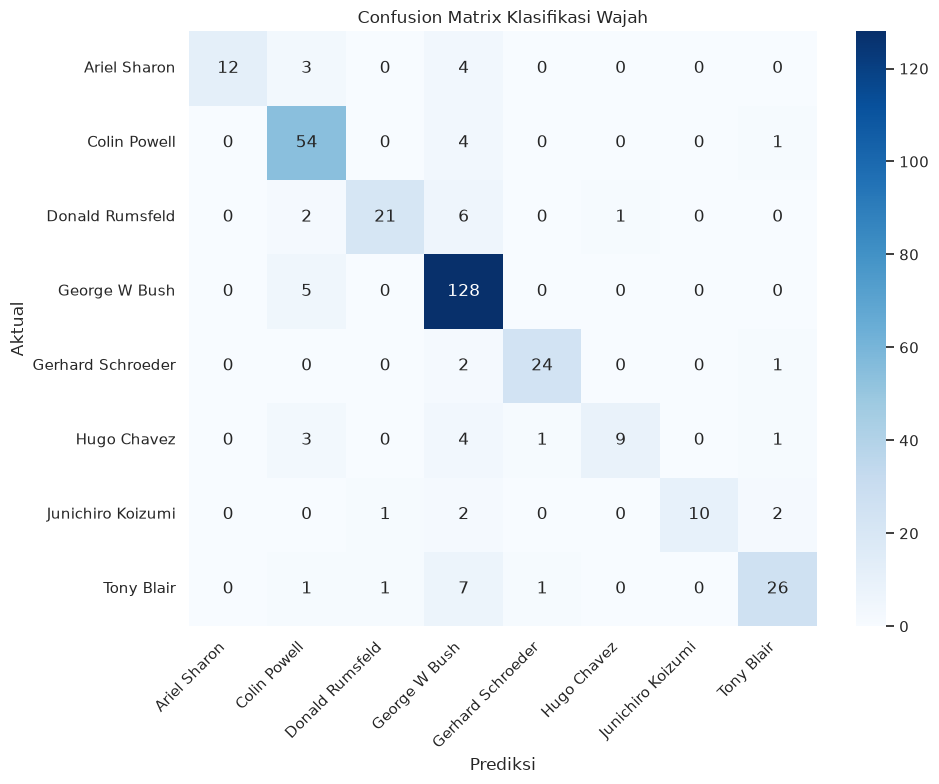

In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=faces.target_names,
    yticklabels=faces.target_names,
)
plt.title("Confusion Matrix Klasifikasi Wajah")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 6. Contoh hasil prediksi

Label hitam berarti prediksi benar, label merah berarti prediksi salah.

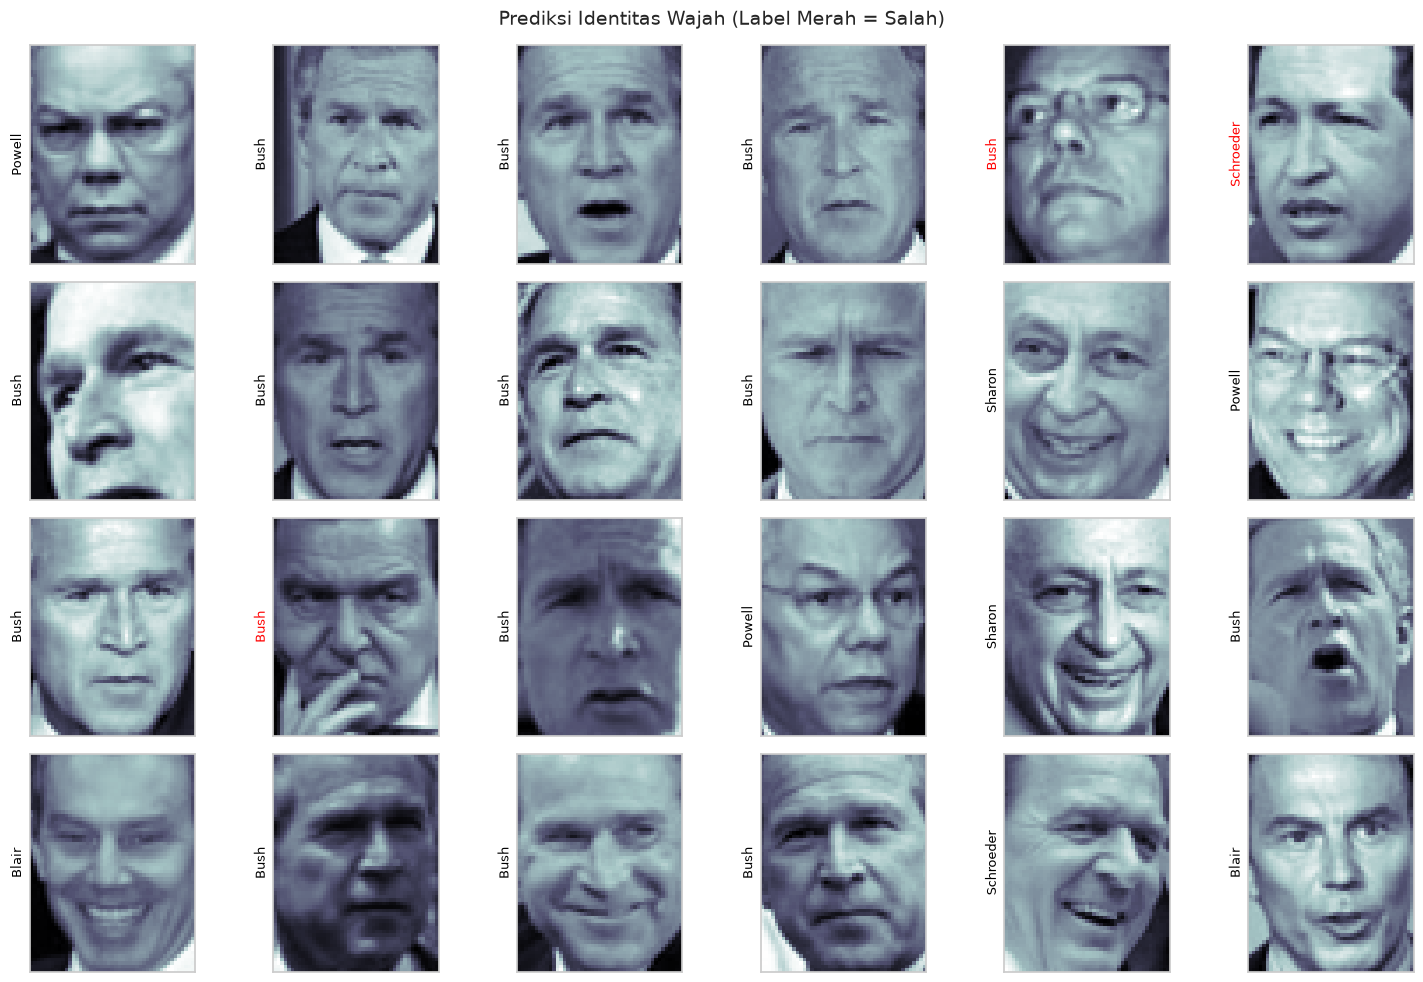

In [8]:
n_rows, n_cols = 4, 6
fig, ax = plt.subplots(n_rows, n_cols, figsize=(15, 10))

h, w = faces.images.shape[1:]
for i, axi in enumerate(ax.flat):
    axi.imshow(X_test[i].reshape(h, w), cmap="bone")
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(
        faces.target_names[y_pred[i]].split()[-1],
        color="black" if y_pred[i] == y_test[i] else "red",
        fontsize=9,
    )

plt.suptitle("Prediksi Identitas Wajah (Label Merah = Salah)", size=14)
plt.tight_layout()
plt.show()

### 7. Variansi yang dijelaskan PCA

In [9]:
pca_fitted = best_model.named_steps["pca"]
explained = pca_fitted.explained_variance_ratio_.sum()

print(f"Jumlah komponen PCA: {pca_fitted.n_components_}")
print(f"Total variansi yang dijelaskan: {explained:.4%}")

Jumlah komponen PCA: 150
Total variansi yang dijelaskan: 93.9973%


### 8. Interpretasi dan kesimpulan

**Hasil**

- Model terbaik: `C=5`, `gamma=0.005`.
- Skor CV terbaik: **0,8309**.
- Akurasi data uji: **0,8427**.
- PCA dengan 150 komponen menjelaskan sekitar **94%** variansi data.
- Waktu GridSearch sekitar **13 detik** pada lingkungan praktikum ini.

**Analisis per kelas**

- George W. Bush memiliki jumlah data uji terbanyak dan recall tinggi, sehingga mendominasi akurasi keseluruhan.
- Beberapa tokoh dengan foto lebih sedikit, seperti Hugo Chavez dan Ariel Sharon, memiliki recall lebih rendah.
- Kesalahan terutama terjadi antara tokoh dengan wajah yang mirip atau pencahayaan/pose yang berbeda.
- `class_weight='balanced'` membantu meningkatkan perhatian pada kelas minoritas, tetapi tidak menghilangkan seluruh bias data.

**Mengapa PCA + SVM bekerja?**

- PCA mengurangi 2.914 fitur piksel menjadi 150 komponen yang menangkap struktur utama wajah.
- Pengurangan dimensi mempercepat pelatihan dan mengurangi noise piksel.
- SVM RBF kemudian membentuk batas keputusan non-linear pada ruang komponen PCA.
- Whitening membuat setiap komponen memiliki skala variansi yang setara.

**Keterbatasan**

- Dataset tidak seimbang; akurasi keseluruhan dapat didominasi kelas mayoritas.
- PCA tidak mempertimbangkan label, sehingga komponen yang penting untuk membedakan tokoh belum tentu dipertahankan.
- SVM RBF sulit diinterpretasikan dan biaya prediksi lebih tinggi daripada model linear.
- Citra wajah sangat dipengaruhi pencahayaan, pose, ekspresi, dan kualitas foto.

**Kesimpulan**

1. Pipeline PCA + SVM RBF mencapai akurasi uji **84,27%** pada 8 tokoh.
2. GridSearchCV menemukan `C=5` dan `gamma=0.005` sebagai kombinasi terbaik.
3. PCA 150 komponen menjelaskan sekitar 94% variansi dan mempercepat pelatihan.
4. Evaluasi per kelas penting karena dataset tidak seimbang.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS11 – Klasifikasi 2, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2
- `scikit-learn` – Labeled Faces in the Wild. https://scikit-learn.org/stable/datasets/real_world.html#the-labeled-faces-in-the-wild-lfw-face-recognition-dataset
- `scikit-learn` – PCA. https://scikit-learn.org/stable/modules/decomposition.html#pca
- `scikit-learn` – GridSearchCV. https://scikit-learn.org/stable/modules/grid_search.html